In [23]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

### grab filepath without QRS annotation (mockup ECG with 1 signal, we only grab ECG1)

In [41]:
filepath = "./src/MITBIH-EKG/04015_ekg.csv"

dat_raw = pd.read_csv(filepath, low_memory=False, index_col=0)
dat_raw

,ECG1,ECG2,qrs_annotation,generic_annotation
0,-0.275,-0.210,NaN,NaN
1,-0.295,-0.200,NaN,NaN
2,-0.310,-0.220,NaN,NaN
3,-0.315,-0.225,NaN,NaN
4,-0.300,-0.215,NaN,NaN
...,...,...,...,...
9205755,-0.765,-1.810,NaN,NaN
9205756,-0.680,-1.560,NaN,NaN
9205757,-0.680,-1.345,NaN,NaN
9205758,-0.670,-1.230,NaN,NaN


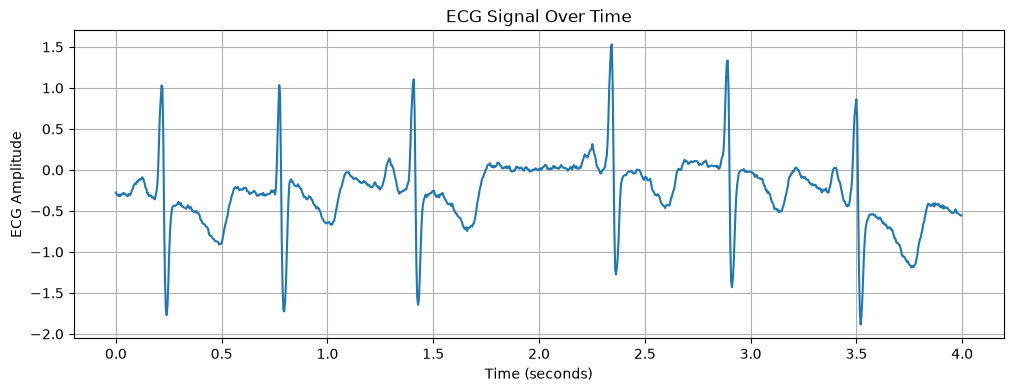

In [67]:
# define the first 1000 YValue (time)
y_val = dat_raw['ECG1'][:1000]

# change to time base
time = np.arange(len(y_val)) / 250

plt.figure(figsize=(12, 4))
plt.plot(time, y_val)

plt.xlabel('Time (seconds)')
plt.ylabel('ECG Amplitude')
plt.title('ECG Signal Over Time')
plt.grid(True)
plt.show()

## Bandpass 5-15 Hz using Butterworth (Pan-Tompkins Algo)

In [68]:
# imports for the pipeline
from scipy.signal import butter, filtfilt, convolve

In [69]:
# pipeline configuration
fs = 250
band_low = 5
band_high = 15
filt_order = 4
derivative_coeff = np.array([2,1,0,-1,-2]) / 8 ## ?????
window_delay = 0.150 ## di minta 150ms 

In [70]:
# 1. Bandpass Filter (5-15 Hz)
nyq = fs / 2
b, a = butter(filt_order, [band_low / nyq, band_high / nyq], btype='band')
ecg_filtered = filtfilt(b, a, dat_raw['ECG1'])

# 2. Derivative Filter
ecg_differentiated = convolve(ecg_filtered, derivative_coeff, mode='same')

# 3. Squaring Function (amplifies high values, forces all positive)
ecg_squared = ecg_differentiated ** 2

# 4. Moving Window Integration (150ms window)
window_size = int(window_delay * fs)  # 37-38 samples
kernel = np.ones(window_size) / window_size
ecg_integrated = convolve(ecg_squared, kernel, mode='same')

In [71]:
x = dat_raw['ECG1']
def bandpass_filter(x, fs, band_low, band_high,filt_order):
    nyq = 0.5*fs
    b,a = butter(filt_order,[band_low/nyq, band_high/nyq], btype="band")
    return filtfilt(b,a,x)

In [73]:
# Call bandpass_filter with all required parameters defined earlier
dat_filt = bandpass_filter(
    x=dat_raw['ECG1'].values,
    fs=fs,
    band_low=band_low,
    band_high=band_high,
    filt_order=filt_order
)

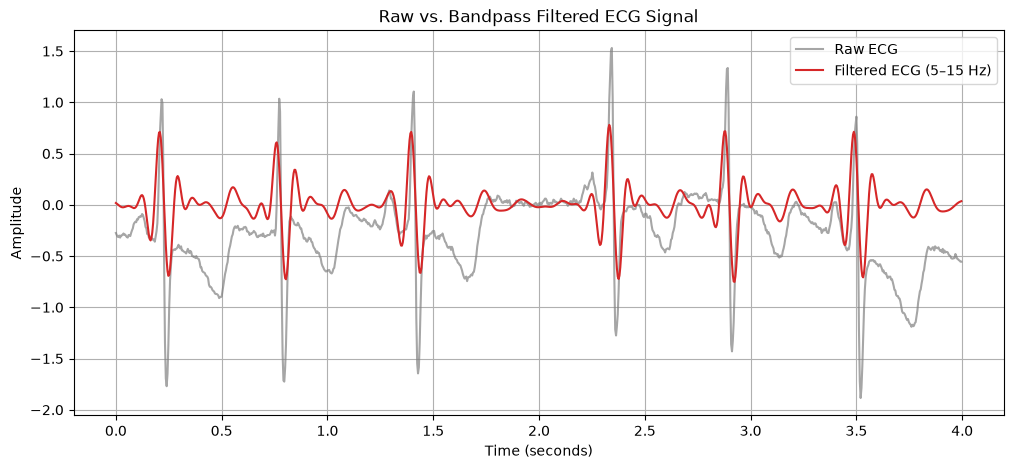

In [78]:
# Select the first 1,000 samples for display
n_samples = 1000
time_segment = np.arange(n_samples) / fs

# Create comparison plot
plt.figure(figsize=(12, 5))
plt.plot(time_segment, dat_raw['ECG1'].iloc[:n_samples], label='Raw ECG', color='gray', alpha=0.7)
plt.plot(time_segment, dat_filt[:n_samples], label='Filtered ECG (5–15 Hz)', color='tab:red')

plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('Raw vs. Bandpass Filtered ECG Signal')
plt.grid(True)
plt.legend(loc='upper right')
plt.show()

<Figure size 1200x600 with 0 Axes>

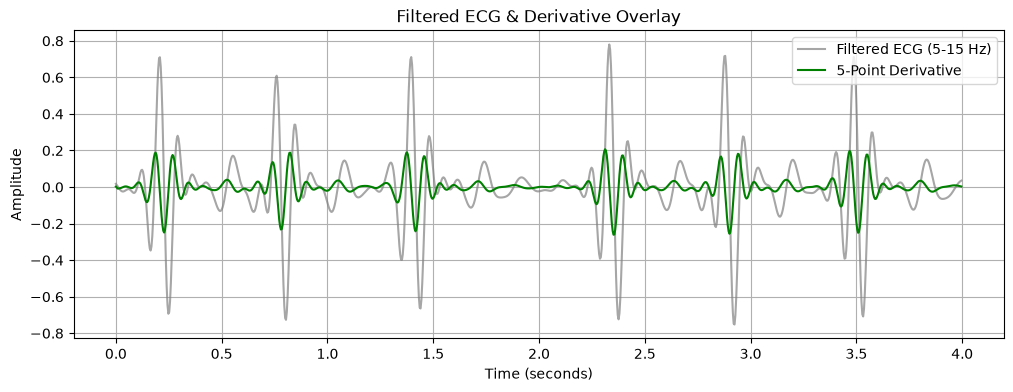

In [82]:
from scipy.signal import convolve  # or np.convolve

## 1. Compute the 5-point derivative
derivative_coeff = np.array([2, 1, 0, -1, -2]) / 8.0
ecg_differentiated = convolve(dat_filt, derivative_coeff, mode='same')

# 2. Select a segment to plot (first 1000 samples = 4 seconds at 250 Hz)
n_samples = 1000
fs = 250
time = np.arange(n_samples) / fs

filt_segment = dat_filt[:n_samples]
diff_segment = ecg_differentiated[:n_samples]

# 3. Plot comparison using subplots
plt.figure(figsize=(12, 6))

plt.figure(figsize=(12, 4))
plt.plot(time, filt_segment, label='Filtered ECG (5-15 Hz)', color='gray', alpha=0.7)
plt.plot(time, diff_segment, label='5-Point Derivative', color='green')

plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('Filtered ECG & Derivative Overlay')
plt.grid(True)
plt.legend(loc='upper right')
plt.show()

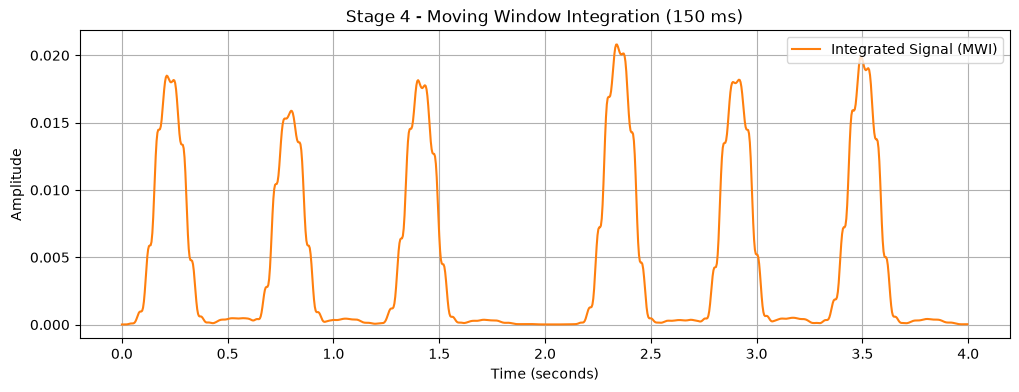

In [83]:
def moving_window_integrator(x, fs=250, window_sec=0.150):
    # Calculate window size (samples) and normalize kernel
    w = int(round(window_sec * fs))
    kernel = np.ones(w) / w
    return convolve(x, kernel, mode='same')

# 1. Apply integration to the squared ECG signal
ecg_integrated = moving_window_integrator(ecg_squared, fs=250, window_sec=0.150)

# 2. Plot segment (first 1000 samples = 4 seconds)
n_samples = 1000
time = np.arange(n_samples) / 250

plt.figure(figsize=(12, 4))
plt.plot(time, ecg_integrated[:n_samples], color='tab:orange', label='Integrated Signal (MWI)')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('Stage 4 - Moving Window Integration (150 ms)')
plt.grid(True)
plt.legend(loc='upper right')
plt.show()

In [101]:
from scipy.signal import find_peaks

def detect_r_peaks(envelope, fs=250,
                    refractory_sec=0.200,
                    search_back_factor=1.66,
                    spki_alpha=0.125, npki_alpha=0.125,
                    t1_factor=0.25, t2_factor=0.50):
    """Detect R-peak sample indices on the QRS envelope using Pan-Tompkins adaptive thresholding.
    """
    n = len(envelope)
    refractory = max(1, int(refractory_sec * fs))

    # Step 1 - Find local peak candidates enforcing refractory distance
    candidates, _ = find_peaks(envelope, distance=refractory)
    if candidates.size == 0:
        return np.array([], dtype=int)

    # Seed SPKI / NPKI safely using percentiles to prevent artifact threshold lockout
    seed_n = min(n, int(5.0 * fs))
    seed = envelope[:seed_n]
    
    # 90th percentile prevents single noise spikes from inflating SPKI
    spki = float(np.percentile(seed, 90)) if len(seed) > 0 else float(np.max(envelope) * 0.5)
    npki = float(np.mean(seed)) + 1e-9

    t1 = npki + t1_factor * (spki - npki)
    t2 = t2_factor * t1

    # Step 2 - Adaptive threshold classification
    peaks = []
    rr_recent = []
    last_accepted = -1

    for cand_idx in candidates:
        cand_val = float(envelope[cand_idx])

        if cand_val > t1:
            peaks.append(int(cand_idx))
            spki = spki_alpha * cand_val + (1 - spki_alpha) * spki
            if last_accepted >= 0:
                rr_recent.append(int(cand_idx) - last_accepted)
                if len(rr_recent) > 8:  # Retain only last 8 intervals
                    rr_recent.pop(0)
            last_accepted = int(cand_idx)
        else:
            # Candidates below T1 update noise level estimation (NPKI)
            npki = npki_alpha * cand_val + (1 - npki_alpha) * npki

        # Recalculate dynamic thresholds
        t1 = npki + t1_factor * (spki - npki)
        t2 = t2_factor * t1

    # Step 3 - Search-back for missed beats in long gaps
    if len(peaks) >= 2 and rr_recent:
        mean_rr = int(np.mean(rr_recent))
        sb_limit = int(search_back_factor * mean_rr)
        extra = []
        
        for i in range(1, len(peaks)):
            gap = peaks[i] - peaks[i - 1]
            if gap > sb_limit:
                lo = peaks[i - 1] + refractory
                hi = min(peaks[i], peaks[i - 1] + sb_limit)
                if hi <= lo:
                    continue
                seg = envelope[lo:hi]
                if len(seg) == 0:
                    continue
                
                sb_val = float(np.max(seg))
                if sb_val > t2:
                    sb_idx = lo + int(np.argmax(seg))
                    extra.append(sb_idx)

        if extra:
            peaks = sorted(set(peaks) | set(extra))

    return np.array(peaks, dtype=int)

In [103]:
# --- 1. Compute Peaks ---
# Detect envelope peaks using the fixed detection function
envelope_peaks = detect_r_peaks(mwi_signal, fs=250)

# --- 2. Align Envelope Peaks to Exact R-Peaks on Filtered ECG ---
# MWI adds a slight phase delay; search in a local ±50 ms window for exact local max
search_radius = int(0.050 * 250)  # 50 ms window (~12 samples)
r_peaks = []

for peak in envelope_peaks:
    left = max(0, peak - search_radius)
    right = min(len(ecg_filtered), peak + search_radius)
    exact_peak = left + np.argmax(ecg_filtered[left:right])
    r_peaks.append(exact_peak)

r_peaks = np.array(r_peaks, dtype=int)

# --- 3. Plotting Setup (First 10 Seconds) ---
fs = 250
start_sec, end_sec = 0, 10
start_idx, end_idx = int(start_sec * fs), int(end_sec * fs)

# Time axis in seconds
t = np.arange(start_idx, end_idx) / fs

# Filter peak indices to display range
display_r_peaks = r_peaks[(r_peaks >= start_idx) & (r_peaks < end_idx)]
display_env_peaks = envelope_peaks[(envelope_peaks >= start_idx) & (envelope_peaks < end_idx)]

# --- 4. Render Plots ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Subplot 1: Filtered ECG + Detected R-peaks
ax1.plot(t, ecg_filtered[start_idx:end_idx], label="Filtered ECG", color="#1f77b4", linewidth=1.2)
ax1.plot(
    display_r_peaks / fs, 
    ecg_filtered[display_r_peaks], 
    "ro", 
    markersize=7, 
    label="Detected R-peaks"
)
ax1.set_title("Filtered ECG Signal with R-Peaks")
ax1.set_ylabel("Amplitude")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")

# Subplot 2: MWI Envelope + Detection Candidates
ax2.plot(t, mwi_signal[start_idx:end_idx], label="MWI Envelope", color="#ff7f0e", linewidth=1.2)
ax2.plot(
    display_env_peaks / fs, 
    mwi_signal[display_env_peaks], 
    "bx", 
    markersize=8, 
    markeredgewidth=2, 
    label="Envelope Trigger Peaks"
)
ax2.set_title("Moving Window Integration (MWI) Envelope")
ax2.set_xlabel("Time (seconds)")
ax2.set_ylabel("Amplitude")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

NameError: name 'mwi_signal' is not defined